# Pandas

## Część I

Będziemy przetwarzać dane z Kaggle odnośnie imion dzieci w USA.

Krok 0: wczytaj pandas

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

Krok 1: wczytaj dane z pliku `US_Baby_Names_right.csv` z katalogu `lab12_files`

Krok 2: przypisz dane do zmiennej `baby_names`. Zobacz jakiego typu dane są przechowywane i ile jest rekordów

Krok 3: podejrzy pierwszych 10 rekordów ze zbioru

Krok 4: usuń kolumny 'Unnamed: 0' oraz 'Id' 

Krok 5: czy w zbiorze jest więcej imion kobiet, czy mężczyzn?

Krok 6: zgrupuj wiersze względem imion i wypisz 10 najczęściej pojawiających się imion.

Krok 7: wyniki z Kroku 6 zaprezentuj na wykresie korzystając z `matplotlib`. Przygotuj trzy wykresy, tj. 10 najczęsciej występujących imion: ogółem, u mężczyzn i u kobiet.

Krok 8: Jak wiele różnych imion występuje w zbiorze?

Krok 9: Przygotuj generator imion, losujący je zgodnie z rozkłądem prawdopodobieństwa otrzymanym na podstawie przetwarzanego pliku

Krok 10: 
- Jakie imie występuje najczęściej?
- Wyznacz średnią, medianę i odchylenie stanadrdowe wystepowania imion.

## Część II

Krok 1: Wczytaj dane

Krok 2: Podejrzyj pierwsze 25 rekordów

Krok 3: Podejrzyj ostatnie 10 rekordów

Krok 4: Ile jest obserwacji w zbiorze? Ile jest kolumn w zbiorze?

Krok 5: Wypisz nazwy kolumn

Krok 6: Ile różnych zawodów jest w zbiorze?

Krok 7: Przygotuj efektywny wykres na którym przedstawisz procetowy udział poszczególnych zawodów w zbiorze na charplocie
Wykorzystaj https://matplotlib.org/examples/pie_and_polar_charts/pie_demo_features.html

Przygotuj dwa wykresy: 
- jeden z wszystkimi zawodami
- drugi z 10 najcześtrzymi zawodami, pozostałem zawody trafiają do kategorii `Inne`

Krok 8: Przygotuj efektywny wykres na którym przedstawisz 10 najczęstrzych zawodów oraz ile pracuje w nich kobiet a ilu meżczyzn
Wykorzystaj https://matplotlib.org/gallery/api/barchart.html#sphx-glr-gallery-api-barchart-py

Krok 9: Przygotuj efektywny wykres na którym przedstawisz średni wiek pracowników danego zawodu

Krok 10: Przygotuj efektywny wykres na którym przedstawisz średni wiek kobiet i mężczyzn wykonujących dany zawód.

## Wykonanie: pliki danych i założenia

Notebook oczekuje plików względnych do katalogu projektu:

- `lab12_files/US_Baby_Names_right.csv` — część I; wymagane kolumny: `Name`, `Gender`, `Count`. Kolumny `Unnamed: 0` i `Id` są opcjonalne i zostaną usunięte.
- `lab12_files/occupation.csv` — część II; nazwa pliku nie została podana w treści zadania. Wymagane kolumny: `occupation`, `age`, `gender` (wielkość liter nie ma znaczenia; obsługiwane są też `job`/`profession` oraz `sex`).

W repozytorium nie ma obecnie żadnego pliku CSV, dlatego wyniki liczbowe i wykresy nie mogą zostać obliczone ani zweryfikowane. Komórki wykonawcze nie próbują wczytać brakujących danych: wypisują dokładną ścieżkę do uzupełnienia.

In [2]:
DATA_DIR = Path("lab12_files")
BABY_NAMES_PATH = DATA_DIR / "US_Baby_Names_right.csv"
OCCUPATIONS_PATH = DATA_DIR / "occupation.csv"


def load_csv(path, *, dataset_name):
    """Load one documented CSV and explain exactly how to fix a missing file."""
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(
            f"{dataset_name} file not found: {path.resolve()}. "
            f"Add the CSV at that path or change its *_PATH variable."
        )
    return pd.read_csv(path)


def find_column(frame, canonical_name, aliases):
    """Return actual column matching one of aliases, ignoring case and spaces."""
    normalized = {str(column).strip().casefold(): column for column in frame.columns}
    for alias in aliases:
        column = normalized.get(alias.casefold())
        if column is not None:
            return column
    expected = ", ".join(aliases)
    available = ", ".join(map(str, frame.columns))
    raise KeyError(
        f"Missing {canonical_name!r} column; expected one of [{expected}]. "
        f"Available columns: [{available}]"
    )


def rename_required_columns(frame, aliases_by_name):
    """Copy frame and normalize required semantic columns to stable names."""
    rename_map = {
        find_column(frame, canonical, aliases): canonical
        for canonical, aliases in aliases_by_name.items()
    }
    return frame.rename(columns=rename_map).copy()

Rekordy: 1016395; różne imiona: 17632
Typy danych:
 Name      string[python]
Year               int64
Gender    string[python]
State             object
Count              int64
dtype: object
Więcej rekordów dla: F
Najczęstsze imię: Riley
Średnia/mediana/odchylenie częstotliwości: 57.644906987295826 8.0 122.0299635081389

Pierwsze 10 wierszy:
        Name  Year Gender State  Count
0      Emma  2004      F    AK     62
1   Madison  2004      F    AK     48
2    Hannah  2004      F    AK     46
3     Grace  2004      F    AK     44
4     Emily  2004      F    AK     41
5   Abigail  2004      F    AK     37
6    Olivia  2004      F    AK     33
7  Isabella  2004      F    AK     30
8    Alyssa  2004      F    AK     29
9    Sophia  2004      F    AK     28

Top 10 imion:
 Name
Riley     1112
Avery     1080
Jordan    1073
Peyton    1064
Hayden    1049
Taylor    1033
Jayden    1031
Alexis     984
Payton     971
Angel      962
dtype: int64

Przykładowe wylosowane imiona:
 0       Nadine
1    

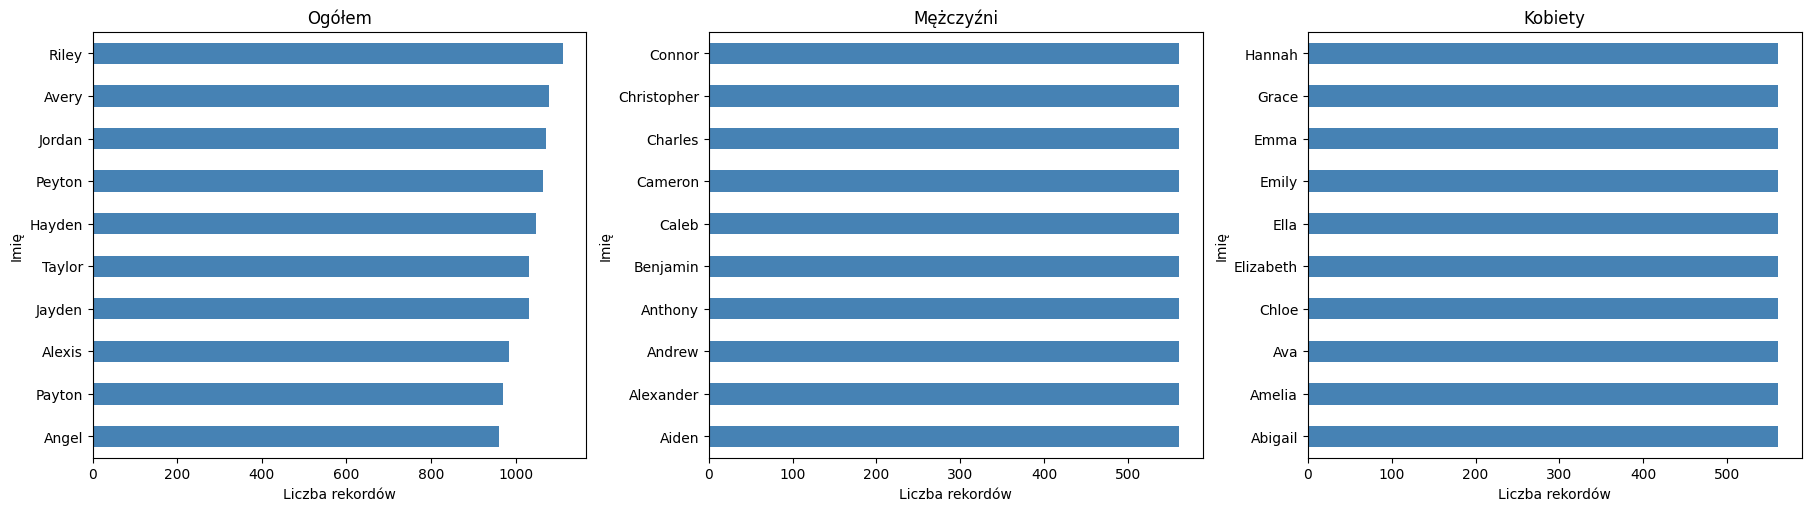

In [3]:
BABY_NAME_ALIASES = {
    "Name": ("name",),
    "Gender": ("gender", "sex"),
    "Count": ("count", "births", "number"),
}


def clean_baby_names(frame):
    """Validate, normalize, and clean baby-name rows before analysis."""
    data = frame.drop(columns=["Unnamed: 0", "Id"], errors="ignore")
    data = rename_required_columns(data, BABY_NAME_ALIASES)
    data["Name"] = data["Name"].astype("string").str.strip()
    data["Gender"] = data["Gender"].astype("string").str.strip().str.upper()
    data["Count"] = pd.to_numeric(data["Count"], errors="coerce")
    data = data.dropna(subset=["Name", "Gender", "Count"])
    data = data.loc[(data["Name"] != "") & (data["Count"] >= 0)].copy()
    if data.empty:
        raise ValueError("Baby-name CSV has no valid rows after cleaning.")
    return data


def baby_name_summary(data, top_n=10):
    """Return all non-graph answers for Część I.

    Frequency means number of dataset rows for a name; generator uses birth Count.
    """
    name_frequency = data.groupby("Name").size().sort_values(ascending=False)
    gender_rows = data["Gender"].value_counts()
    return {
        "rows": len(data),
        "dtypes": data.dtypes,
        "more_name_rows_for": gender_rows.index[0],
        "rows_by_gender": gender_rows,
        "top_names": name_frequency.head(top_n),
        "unique_names": data["Name"].nunique(),
        "most_frequent_name": name_frequency.index[0],
        "frequency_mean": name_frequency.mean(),
        "frequency_median": name_frequency.median(),
        "frequency_std": name_frequency.std(),
    }


def sample_baby_names(data, n=1, random_state=None):
    """Sample names with probability proportional to total recorded births."""
    weights = data.groupby("Name")["Count"].sum()
    if weights.sum() <= 0:
        raise ValueError("Baby-name Count values must sum to more than zero.")
    return pd.Series(
        weights.index.to_numpy()[np.random.default_rng(random_state).choice(
            len(weights), size=n, p=(weights / weights.sum()).to_numpy()
        )],
        name="sampled_name",
    )


def plot_top_baby_names(data, top_n=10):
    """Plot overall, male, and female top names by row frequency."""
    groups = [("Ogółem", data), ("Mężczyźni", data[data["Gender"] == "M"]),
              ("Kobiety", data[data["Gender"] == "F"])]
    fig, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)
    for axis, (label, subset) in zip(axes, groups):
        counts = subset.groupby("Name").size().nlargest(top_n).sort_values()
        counts.plot.barh(ax=axis, color="steelblue")
        axis.set(title=label, xlabel="Liczba rekordów", ylabel="Imię")
    return fig, axes


if BABY_NAMES_PATH.is_file():
    baby_names = clean_baby_names(load_csv(BABY_NAMES_PATH, dataset_name="Baby names"))
    baby_results = baby_name_summary(baby_names)
    print(f"Rekordy: {baby_results['rows']}; różne imiona: {baby_results['unique_names']}")
    print("Typy danych:\n", baby_results["dtypes"])
    print("Więcej rekordów dla:", baby_results["more_name_rows_for"])
    print("Najczęstsze imię:", baby_results["most_frequent_name"])
    print("Średnia/mediana/odchylenie częstotliwości:",
          baby_results["frequency_mean"], baby_results["frequency_median"], baby_results["frequency_std"])
    print("\nPierwsze 10 wierszy:\n", baby_names.head(10))
    print("\nTop 10 imion:\n", baby_results["top_names"])
    print("\nPrzykładowe wylosowane imiona:\n", sample_baby_names(baby_names, n=10, random_state=42))
    plot_top_baby_names(baby_names)
else:
    print(f"Część I pominięta: brak pliku {BABY_NAMES_PATH.resolve()}")

In [4]:
OCCUPATION_ALIASES = {
    "occupation": ("occupation", "job", "profession"),
    "age": ("age",),
    "gender": ("gender", "sex"),
}


def clean_occupations(frame):
    """Validate and clean occupation, age, and gender columns for Część II."""
    data = rename_required_columns(frame, OCCUPATION_ALIASES)
    data["occupation"] = data["occupation"].astype("string").str.strip()
    data["gender"] = data["gender"].astype("string").str.strip().str.upper()
    data["age"] = pd.to_numeric(data["age"], errors="coerce")
    data = data.dropna(subset=["occupation", "gender", "age"])
    data = data.loc[(data["occupation"] != "") & (data["age"] >= 0)].copy()
    if data.empty:
        raise ValueError("Occupation CSV has no valid rows after cleaning.")
    return data


def occupation_counts_with_other(data, top_n=10):
    counts = data["occupation"].value_counts()
    top = counts.head(top_n)
    other_count = counts.iloc[top_n:].sum()
    return pd.concat([top, pd.Series({"Inne": other_count})]) if other_count else top


def plot_occupation_shares(data, top_n=10):
    """Plot share for all occupations and top occupations plus Inne."""
    all_counts = data["occupation"].value_counts()
    grouped_counts = occupation_counts_with_other(data, top_n)
    fig, axes = plt.subplots(1, 2, figsize=(16, 8), constrained_layout=True)
    for axis, counts, title in zip(
        axes,
        (all_counts, grouped_counts),
        ("Wszystkie zawody", f"Top {top_n} zawodów + Inne"),
    ):
        axis.pie(counts, labels=counts.index, autopct="%1.1f%%", startangle=90,
                 textprops={"fontsize": 8})
        axis.set_title(title)
    return fig, axes


def plot_top_occupation_gender_counts(data, top_n=10):
    """Plot counts of each available gender for top occupations."""
    top_jobs = data["occupation"].value_counts().head(top_n).index
    counts = pd.crosstab(data["occupation"], data["gender"]).reindex(top_jobs, fill_value=0)
    ax = counts.plot.bar(figsize=(12, 6), color=["#4c78a8", "#f58518", "#54a24b"])
    ax.set(title=f"Top {top_n} zawodów według płci", xlabel="Zawód", ylabel="Liczba pracowników")
    ax.tick_params(axis="x", rotation=45)
    return ax


def plot_mean_age(data):
    """Plot mean age by occupation, overall and split by gender."""
    overall = data.groupby("occupation")["age"].mean().sort_values()
    by_gender = data.pivot_table(index="occupation", columns="gender", values="age", aggfunc="mean")
    by_gender = by_gender.loc[overall.index]
    fig, axes = plt.subplots(1, 2, figsize=(16, max(5, len(overall) * 0.35)), constrained_layout=True)
    overall.plot.barh(ax=axes[0], color="slateblue")
    axes[0].set(title="Średni wiek według zawodu", xlabel="Średni wiek", ylabel="Zawód")
    by_gender.plot.barh(ax=axes[1])
    axes[1].set(title="Średni wiek według zawodu i płci", xlabel="Średni wiek", ylabel="Zawód")
    return fig, axes


if OCCUPATIONS_PATH.is_file():
    occupations = clean_occupations(load_csv(OCCUPATIONS_PATH, dataset_name="Occupation"))
    print("Pierwsze 25 wierszy:\n", occupations.head(25))
    print("\nOstatnie 10 wierszy:\n", occupations.tail(10))
    print(f"\nObserwacje: {occupations.shape[0]}; kolumny: {occupations.shape[1]}")
    print("Nazwy kolumn:", occupations.columns.tolist())
    print("Różne zawody:", occupations["occupation"].nunique())
    plot_occupation_shares(occupations)
    plot_top_occupation_gender_counts(occupations)
    plot_mean_age(occupations)
else:
    print(f"Część II pominięta: brak pliku {OCCUPATIONS_PATH.resolve()}")

Część II pominięta: brak pliku /Users/pawel/Documents/GitHub/UJ/effective_python/lab12_files/occupation.csv
